# Great Britain Road Collision Profiles

**Question:** Which lighting, road-type and speed-limit profiles account for the largest numbers of fatal or serious reported collisions in Great Britain, 2021–2025?

**Consumer:** a road safety analyst selecting groups for further local investigation. The primary output distinguishes absolute severe-case counts, within-profile severity and shares of all severe cases. It does not rank exposure-adjusted risk or prescribe interventions.

This notebook reads validated Gold outputs. Run the project first, then **Restart Kernel and Run All**. Figures use reported, unadjusted severity.

In [1]:
from pathlib import Path
import os, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/dev.json").exists())
environment = os.environ.get("DAT535_ENV", "dev")
assert environment in ["dev", "prod"]
settings = json.loads((root / "config" / f"{environment}.json").read_text())
gold_root = Path(os.environ.get("STATS19_GOLD_DIR", root / settings["gold"]))
pointer = json.loads((gold_root / "latest_successful.json").read_text())
gold = Path(pointer["path"])
gold_report = json.loads((gold / "quality_report.json").read_text())
assert gold_report["status"] == "passed" and gold_report["run_id"] == pointer["run_id"]
silver_report = json.loads((Path(gold_report["silver_path"]) / "quality_report.json").read_text())
assert silver_report["status"] == "passed"
print("Environment:", environment, "| Gold run:", gold_report["run_id"])
display(pd.DataFrame([gold_report["source_totals"]]))

Environment: dev | Gold run: 20261110T150552746288Z


,collisions,casualties,fatal_or_serious
0,513801,652821,124366


## Quality before interpretation

The tables retain separate collision, vehicle and casualty grains. Vehicle and casualty information is reduced to collision grain before enrichment. The checks below are generated for each run, rather than copied into this notebook.

In [2]:
quality = []
for name, metrics in silver_report["tables"].items():
    quality.append({"table": name, "input_rows": metrics["rows"],
                    "output_rows": metrics["output_rows"], "missing_keys": metrics["missing_keys"],
                    "duplicate_key_excess": metrics["duplicate_key_excess"]})
display(pd.DataFrame(quality))
display(pd.DataFrame([silver_report["relationships"]]).T.rename(columns={0: "records"}))

,table,input_rows,output_rows,missing_keys,duplicate_key_excess
0,collisions,513801,513801,0,0
1,vehicles,937265,937265,0,0
2,casualties,652821,652821,0,0


,records
vehicles_without_collision,0
vehicles_year_mismatches,0
casualties_without_collision,0
casualties_year_mismatches,0
casualties_without_vehicle,0
observed_vehicle_count_mismatches,0
observed_casualty_count_mismatches,0


## Collision profile concentration

Each profile combines lighting, road type and speed limit. The first percentage is severe cases divided by all collisions within the profile. The second is the profile's severe cases divided by all severe cases in the snapshot. Unknown categories remain in the table. Rank by absolute severe-case count to answer the main question, then inspect both percentages.

,profile,collision_count,fatal_or_serious_collision_count,fatal_or_serious_percentage,share_of_all_collisions_percentage,share_of_all_fatal_or_serious_percentage,severe_minus_all_collision_share_pp
28,Daylight / Single carriageway / 30 mph,156048,35130,22.512,30.371,28.247,-2.124
31,Daylight / Single carriageway / 60 mph,40725,14458,35.502,7.926,11.625,3.699
65,Darkness - lights lit / Single carriageway / 3...,50163,13817,27.544,9.763,11.110,1.347
27,Daylight / Single carriageway / 20 mph,45586,9436,20.699,8.872,7.587,-1.285
29,Daylight / Single carriageway / 40 mph,18482,5167,27.957,3.597,4.155,0.558
133,Darkness - no lighting / Single carriageway / ...,13484,5006,37.125,2.624,4.025,1.401
25,Daylight / Dual carriageway / 70 mph,16566,3879,23.415,3.224,3.119,-0.105
64,Darkness - lights lit / Single carriageway / 2...,16176,3724,23.022,3.148,2.994,-0.154
30,Daylight / Single carriageway / 50 mph,9649,3193,33.092,1.878,2.567,0.689
21,Daylight / Dual carriageway / 30 mph,14937,2906,19.455,2.907,2.337,-0.571


Top five profiles: 78,008 severe cases; overall share 62.725%.


**Largest recorded burden:** Daylight / Single carriageway / 30 mph contains 35,130 severe cases among 156,048 reported collisions (22.512% within the profile).

**Counts and proportions differ:** among the leading ten profiles by severe count, Darkness - no lighting / Single carriageway / 60 mph has a within-profile percentage of 37.125% and 5,006 severe cases. This is a descriptive comparison, not an exposure-adjusted risk ranking.

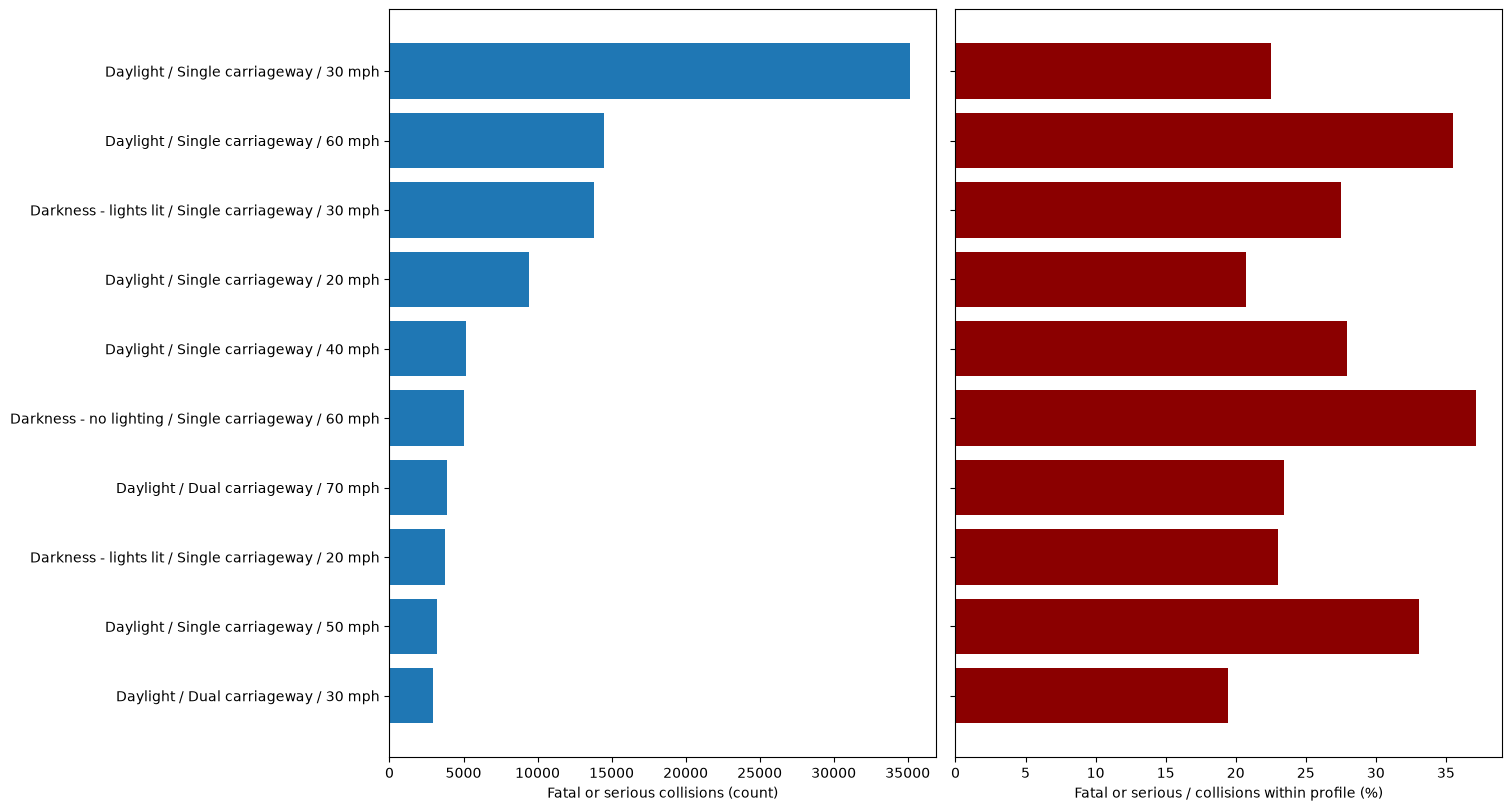

In [3]:
profiles = pd.read_csv(gold / "collision_profiles.csv").sort_values(
    ["fatal_or_serious_collision_count", "collision_count"], ascending=[False, False])
profiles["profile"] = profiles.apply(lambda r: f"{r.light_conditions_label} / {r.road_type_label} / " +
    ("Unknown speed" if pd.isna(r.speed_limit_mph_clean) else f"{r.speed_limit_mph_clean:g} mph"), axis=1)
columns = ["profile", "collision_count", "fatal_or_serious_collision_count",
           "fatal_or_serious_percentage", "share_of_all_collisions_percentage",
           "share_of_all_fatal_or_serious_percentage", "severe_minus_all_collision_share_pp"]
display(profiles[columns].head(10))
top_five = int(profiles.head(5).fatal_or_serious_collision_count.sum())
all_severe = gold_report["source_totals"]["fatal_or_serious"]
share_text = f"{100 * top_five / all_severe:.3f}%" if all_severe else "undefined (no severe collisions)"
print(f"Top five profiles: {top_five:,} severe cases; overall share {share_text}.")
from IPython.display import Markdown
largest = profiles.iloc[0]
higher_percentage = profiles.head(10).sort_values("fatal_or_serious_percentage", ascending=False).iloc[0]
display(Markdown(f"**Largest recorded burden:** {largest['profile']} contains "
    f"{int(largest['fatal_or_serious_collision_count']):,} severe cases among "
    f"{int(largest['collision_count']):,} reported collisions "
    f"({largest['fatal_or_serious_percentage']:.3f}% within the profile)."))
display(Markdown(f"**Counts and proportions differ:** among the leading ten profiles by severe count, "
    f"{higher_percentage['profile']} has a within-profile percentage of "
    f"{higher_percentage['fatal_or_serious_percentage']:.3f}% and "
    f"{int(higher_percentage['fatal_or_serious_collision_count']):,} severe cases. "
    "This is a descriptive comparison, not an exposure-adjusted risk ranking."))
chart = profiles.head(10).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharey=True, layout="constrained")
positions = list(range(len(chart)))
axes[0].barh(positions, chart.fatal_or_serious_collision_count)
axes[0].set_yticks(positions, chart.profile)
axes[0].set(xlabel="Fatal or serious collisions (count)")
axes[1].barh(positions, chart.fatal_or_serious_percentage, color="darkred")
axes[1].set(xlabel="Fatal or serious / collisions within profile (%)")
plt.show()

## Answer to the research question

**Daylight / Single carriageway / 30 mph accounts for the largest number of fatal or serious reported collisions: 35,130, or 28.247% of all severe collisions.** The five leading profiles together contain 78,008 severe collisions (62.725%).

The leading profile's within-profile severe proportion is 22.512%, compared with 24.205% across the snapshot. Its share of all recorded collisions is 30.371%. Its large severe caseload therefore accompanies a large recorded collision population; it does not establish a higher probability of a severe outcome than the overall recorded-collision reference.

### Does the pooled ranking hold each year?

The following profiles were selected from the pooled period, then followed in each year. Ranks use severe-case counts, with collision counts and profile codes breaking ties. The share gap is the share of severe collisions minus the share of all recorded collisions, calculated against each year's totals.

| Pooled leading profile | Years observed | Annual rank range | Years with positive / negative share gap |
|---|---|---:|---:|
| Daylight / Single carriageway / 30 mph | 2021, 2022, 2023, 2024, 2025 | 1–1 | 0 / 5 |
| Daylight / Single carriageway / 60 mph | 2021, 2022, 2023, 2024, 2025 | 2–2 | 5 / 0 |
| Darkness - lights lit / Single carriageway / 30 mph | 2021, 2022, 2023, 2024, 2025 | 3–3 | 5 / 0 |
| Daylight / Single carriageway / 20 mph | 2021, 2022, 2023, 2024, 2025 | 4–4 | 0 / 5 |
| Daylight / Single carriageway / 40 mph | 2021, 2022, 2023, 2024, 2025 | 5–5 | 5 / 0 |

**The same five profiles occupy ranks 1–5 in the same order in every year from 2021 to 2025.** This supports the descriptive consistency of the pooled result within the observed period. It is not independent validation or evidence that reporting changes have no effect.

### What should an analyst do with this result?

Use the largest severe-case groups to select where to investigate the recorded burden, and inspect within-profile severity alongside counts to identify different analytical priorities. Next, disaggregate these groups by location and year, review recording and road context, and obtain traffic volumes or distance travelled before comparing exposure-adjusted risk or choosing an intervention. The lighting, road-type and speed-limit associations cannot identify the effect of changing any one of those conditions.

The following temporal, weather and vehicle summaries provide supplementary context.


### Reference population and annual check

Compare a profile's share of all reported collisions with its share of severe cases. Their difference is in percentage points. It describes over- or under-representation among recorded severe cases, not traffic risk or statistical significance.

Annual reference totals are recalculated within each year. The profiles are selected using the pooled period, then followed across the same years. This is a descriptive sensitivity check, not out-of-sample validation. Reporting-system changes and case composition can still affect comparisons.

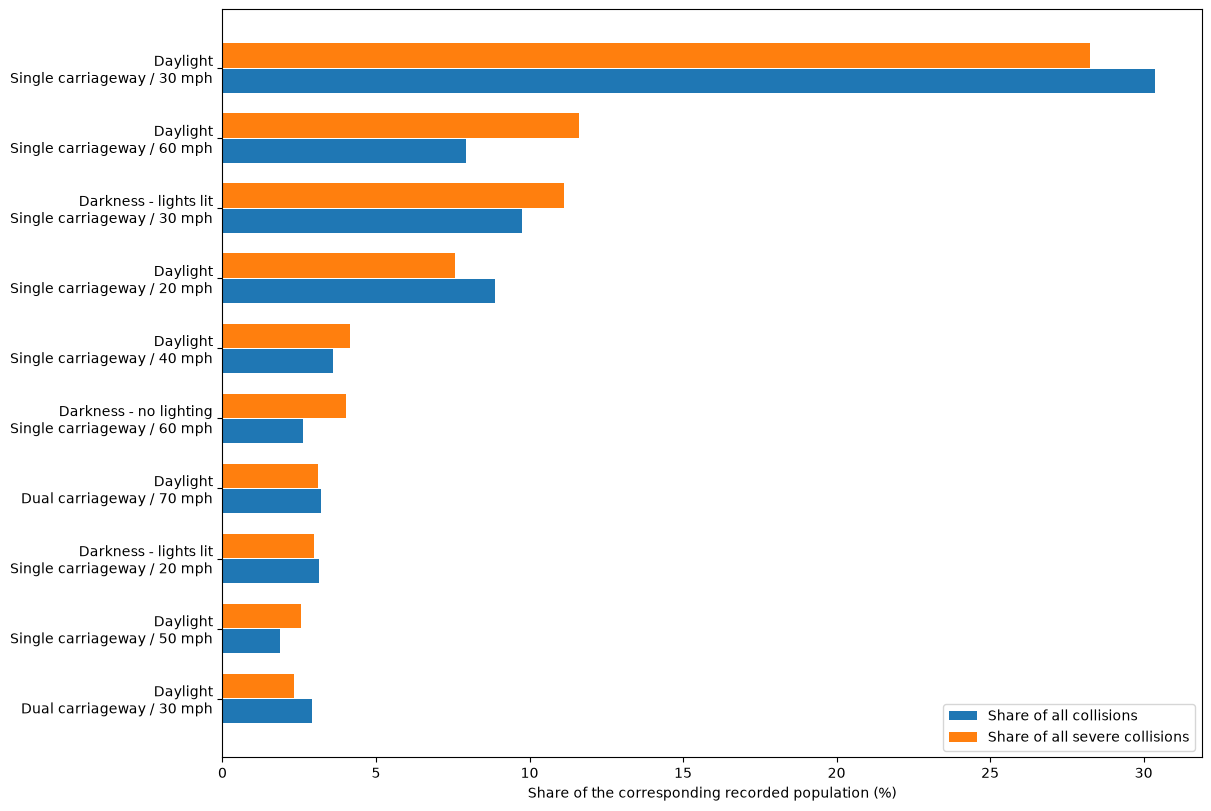

,collision_year,collision_count,fatal_or_serious_collision_count,severe_count_rank,share_of_all_collisions_percentage,share_of_all_fatal_or_serious_percentage,severe_minus_all_collision_share_pp
24,2021,33077,6880,1,32.721,30.231,-2.490
181,2022,33327,7322,1,31.439,29.364,-2.075
342,2023,31401,7048,1,30.119,28.237,-1.881
503,2024,29195,6741,1,28.927,26.890,-2.037
667,2025,29048,7139,1,28.612,26.794,-1.818


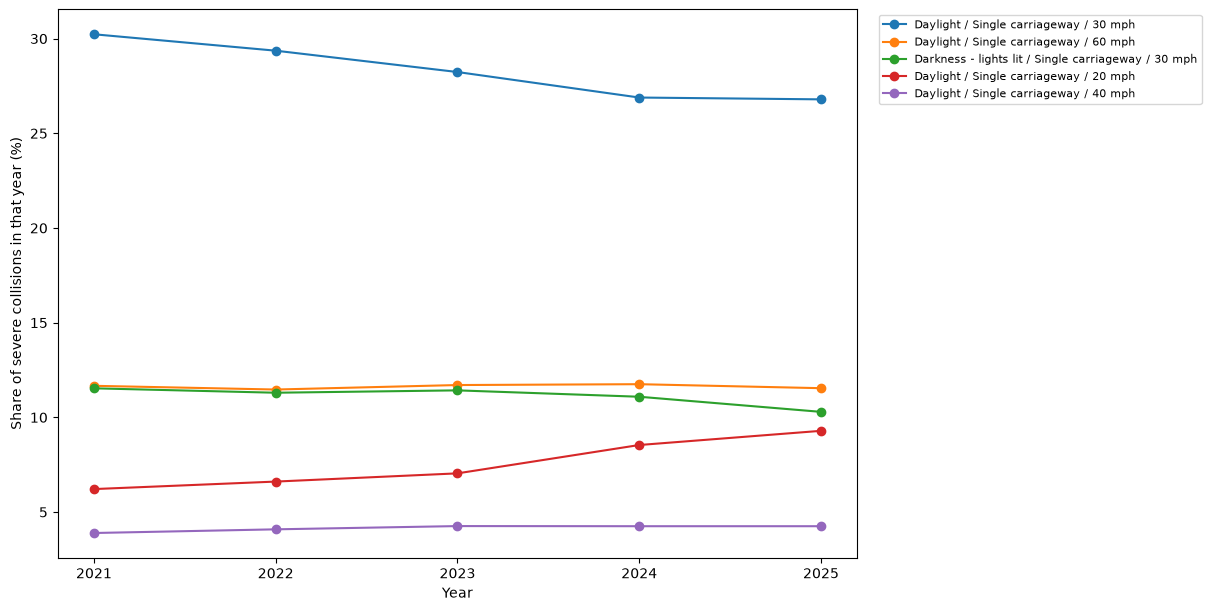

In [4]:
reference = profiles.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(12, 8), layout="constrained")
y = list(range(len(reference)))
ax.barh([v - 0.18 for v in y], reference.share_of_all_collisions_percentage, height=0.35, label="Share of all collisions")
ax.barh([v + 0.18 for v in y], reference.share_of_all_fatal_or_serious_percentage, height=0.35, label="Share of all severe collisions")
ax.set_yticks(y, reference.profile.str.replace(" / ", "\n", n=1))
ax.set(xlabel="Share of the corresponding recorded population (%)")
ax.legend()
plt.show()
annual = pd.read_csv(gold / "collision_profiles_by_year.csv").sort_values(
    ["collision_year", "fatal_or_serious_collision_count", "collision_count", "light_conditions", "road_type", "speed_limit_mph_clean"],
    ascending=[True, False, False, True, True, True])
annual["profile"] = annual.apply(lambda r: f"{r.light_conditions_label} / {r.road_type_label} / " +
    ("Unknown speed" if pd.isna(r.speed_limit_mph_clean) else f"{r.speed_limit_mph_clean:g} mph"), axis=1)
annual["severe_count_rank"] = annual.groupby("collision_year").cumcount() + 1
leading = profiles.iloc[0]["profile"]
display(annual.loc[annual.profile == leading,
    ["collision_year", "collision_count", "fatal_or_serious_collision_count", "severe_count_rank",
     "share_of_all_collisions_percentage", "share_of_all_fatal_or_serious_percentage", "severe_minus_all_collision_share_pp"]])
fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
for label in profiles.profile.head(5):
    data = annual[annual.profile == label].sort_values("collision_year")
    ax.plot(data.collision_year, data.share_of_all_fatal_or_serious_percentage, marker="o", label=label)
ax.set(xlabel="Year", ylabel="Share of severe collisions in that year (%)")
ax.set_xticks(sorted(annual.collision_year.unique()))
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
plt.show()

## Temporal patterns

Collision volume and the percentage classified fatal or serious answer different questions. Monthly volume is not adjusted for traffic exposure, month length or changes in reporting. Severity recording practices can affect comparisons between years.

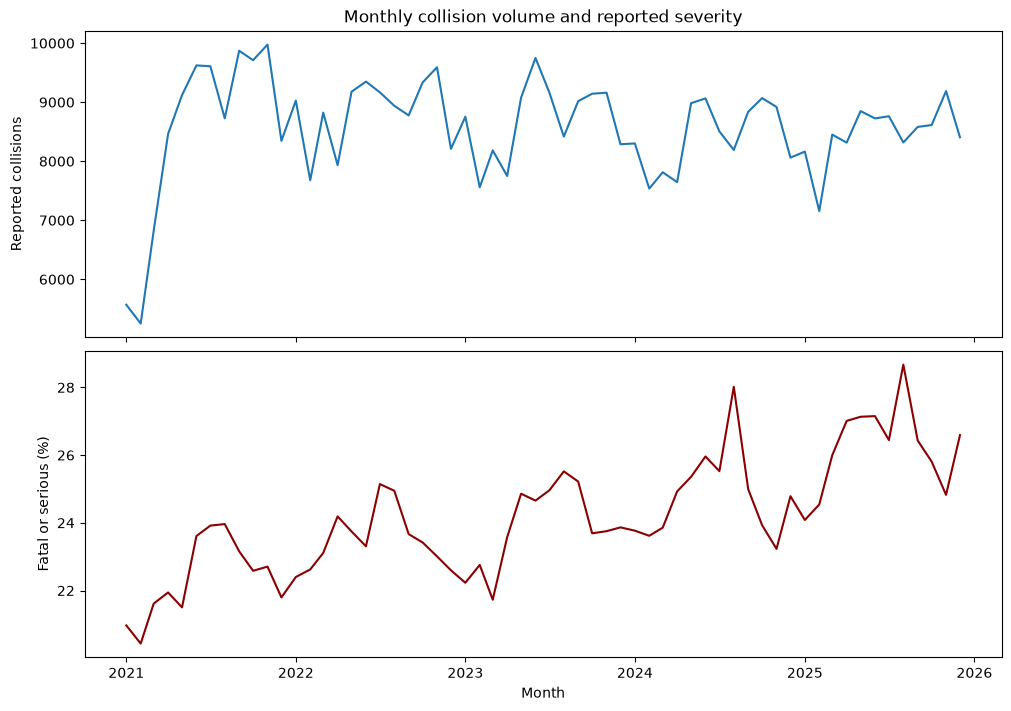

,period,collision_count,fatal_or_serious_percentage
0,2021-01-01,5570,20.969
1,2021-02-01,5251,20.434
2,2021-03-01,6824,21.615
3,2021-04-01,8463,21.943
4,2021-05-01,9120,21.502


In [5]:
monthly = pd.read_csv(gold / "monthly.csv")
monthly["period"] = pd.to_datetime(dict(year=monthly.collision_year, month=monthly.month, day=1))
monthly = monthly.sort_values("period")
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, layout="constrained")
axes[0].plot(monthly.period, monthly.collision_count)
axes[0].set(ylabel="Reported collisions", title="Monthly collision volume and reported severity")
axes[1].plot(monthly.period, monthly.fatal_or_serious_percentage, color="darkred")
axes[1].set(ylabel="Fatal or serious (%)", xlabel="Month")
plt.show()
display(monthly[["period", "collision_count", "fatal_or_serious_percentage"]].head())

## Environmental conditions

The denominator is the number of recorded collisions in each category. A higher percentage in a category is an association within this dataset, not evidence that the condition causes severe collisions. Always inspect group counts alongside percentages.

,weather_conditions_label,collision_count,fatal_or_serious_collision_count,fatal_or_serious_percentage
9,Unknown,14566,1707,11.719
0,Data missing or out of range,12,2,16.667
6,Snowing + high winds,238,46,19.328
8,Other,15955,3164,19.831
3,Snowing no high winds,1791,406,22.669
2,Raining no high winds,55834,13404,24.007
1,Fine no high winds,413632,102325,24.738
5,Raining + high winds,5173,1385,26.774
7,Fog or mist,2128,597,28.055
4,Fine + high winds,4472,1330,29.741


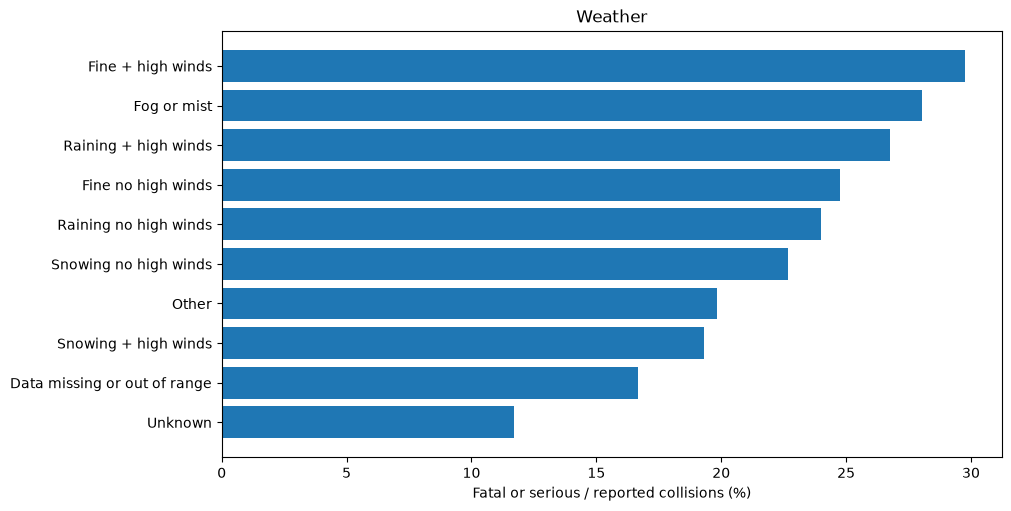

,light_conditions_label,collision_count,fatal_or_serious_collision_count,fatal_or_serious_percentage
5,Darkness - lighting unknown,8596,1707,19.858
1,Daylight,368193,85402,23.195
2,Darkness - lights lit,105834,26578,25.113
3,Darkness - lights unlit,3706,1080,29.142
0,Data missing or out of range,34,10,29.412
4,Darkness - no lighting,27438,9589,34.948


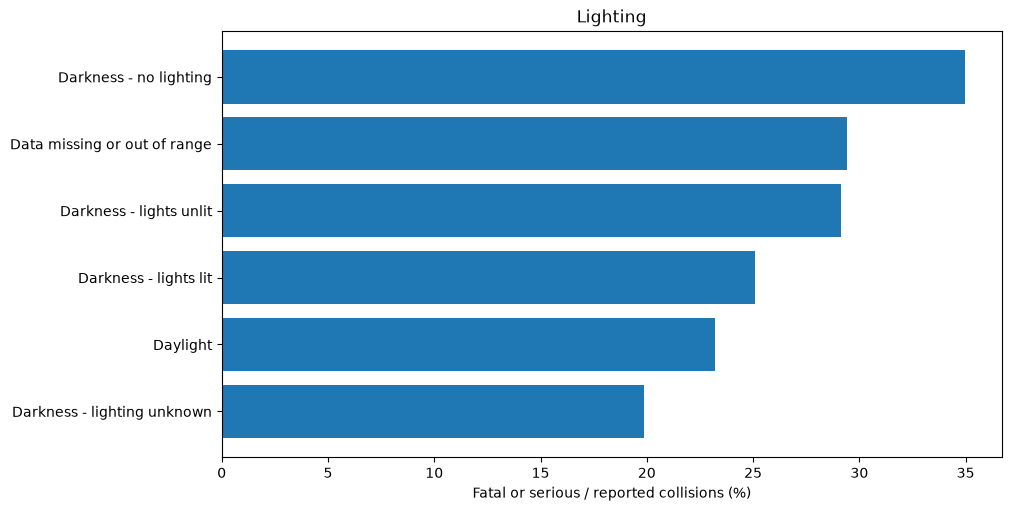

In [6]:
for name, label in [("weather", "weather_conditions_label"), ("lighting", "light_conditions_label")]:
    table = pd.read_csv(gold / f"{name}.csv").sort_values("fatal_or_serious_percentage")
    display(table[[label, "collision_count", "fatal_or_serious_collision_count", "fatal_or_serious_percentage"]])
    fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
    ax.barh(table[label], table.fatal_or_serious_percentage)
    ax.set(xlabel="Fatal or serious / reported collisions (%)", title=name.title())
    plt.show()

## Road and vehicle characteristics

Missing speed limits are retained as a separate group. Vehicle groups count each collision once per vehicle type. They overlap when several types are involved, so their counts cannot be summed into an overall total.

In [7]:
display(pd.read_csv(gold / "speed_limit.csv"))
display(pd.read_csv(gold / "road_type.csv"))
vehicle_types = pd.read_csv(gold / "vehicle_type.csv")
display(vehicle_types[["vehicle_type_label", "collision_count", "fatal_or_serious_percentage"]].sort_values("collision_count", ascending=False))

,speed_limit_mph_clean,collision_count,fatal_or_serious_collision_count,casualty_count,fatal_casualty_count,serious_casualty_count,mean_vehicles_involved,fatal_or_serious_percentage
0,NaN,3,1,3,0,1,1.000000,33.333
1,20.0,88096,17314,98837,423,17521,1.742883,19.654
2,30.0,267325,60547,324295,2392,61996,1.797034,22.649
3,40.0,44750,11495,61137,850,12057,1.919240,25.687
4,50.0,22666,6425,33116,704,6867,1.988176,28.346
5,60.0,62703,21628,92367,2629,23405,1.793503,34.493
6,70.0,28258,6956,43066,1035,7164,2.120497,24.616


,road_type,road_type_label,collision_count,fatal_or_serious_collision_count,casualty_count,fatal_casualty_count,serious_casualty_count,mean_vehicles_involved,fatal_or_serious_percentage
0,1,Roundabout,31178,5365,37451,169,5507,1.882834,17.208
1,2,One way street,11550,2050,13000,41,2110,1.681558,17.749
2,3,Dual carriageway,76119,17426,105094,1650,17881,1.978021,22.893
3,6,Single carriageway,373065,96767,471450,6059,100693,1.792535,25.938
4,7,Slip road,8829,1584,11648,94,1628,1.892966,17.941
5,9,Unknown,13060,1174,14178,20,1192,1.771057,8.989


,vehicle_type_label,collision_count,fatal_or_serious_percentage
7,Car,433442,22.419
1,Pedal cycle,79812,25.619
13,Van / Goods 3.5 tonnes mgw or under,56893,22.709
3,Motorcycle 125cc and under,44144,23.976
5,Motorcycle over 500cc,22350,52.201
6,Taxi/Private hire car,15053,18.966
9,Bus or coach (17 or more pass seats),14926,23.516
15,Goods 7.5 tonnes mgw and over,12518,30.316
4,Motorcycle over 125cc and up to 500cc,9475,37.773
18,Personal powered transporter,6858,30.782


## Missing ages and data retention

The official source age code `-1` means missing or out of range. Source values are preserved; separate clean columns exclude negative values from age calculations. Zero is valid for a casualty. An average of known ages would require its own known-age denominator and may not represent missing records.

In [8]:
display(pd.DataFrame({name: silver_report["tables"][name]["age_quality"] for name in ["vehicles", "casualties"]}).T)
print("Missing coordinates:", {k: v for k, v in silver_report["tables"]["collisions"]["missing_important_fields"].items() if k in ["latitude", "longitude"]})
print("Speed-limit quality:", silver_report["tables"]["collisions"]["speed_limit_quality"])

,source_missing_or_out_of_range_code,unexpected_negative_values,source_nulls,clean_nulls,minimum_recorded_age,maximum_recorded_age
vehicles,142240,0,0,142240,1,105
casualties,14106,0,0,14106,0,105


Missing coordinates: {'longitude': 53, 'latitude': 53}
Speed-limit quality: {'coded_missing_or_unknown': 3, 'unrecognised_values': 0, 'clean_nulls': 3}


## Engineering evidence and interpretation limits

Parquet preserves typed fields and allows selective column reads. A formatted enrichment plan is saved with Silver and a monthly aggregation plan with Gold. Recorded durations are measurements of these runs, not evidence of an optimisation without a controlled comparison.

The current implementation recalculates a fixed snapshot on one VM. Growth, late corrections and schema changes would require renewed partitioning, resource and ingestion decisions. The project does not impute ages, estimate traffic exposure, establish causal effects or apply severity adjustments.

In [9]:
print("Silver seconds:", silver_report["elapsed_seconds"])
print("Gold seconds:", gold_report["elapsed_seconds"])
print("Silver Parquet bytes:", silver_report["output_bytes"])
print("Gold tables reconciled to Silver:")
display(pd.DataFrame(gold_report["tables"]).T)
plan = (Path(gold_report["silver_path"]) / "enrichment_plan.txt").read_text()
print("Selected plan operators:")
print("\n".join(line for line in plan.splitlines() if any(op in line for op in ["HashAggregate", "HashJoin", "Exchange", "InMemoryTableScan"])))

Silver seconds: 59.49
Gold seconds: 19.48
Silver Parquet bytes: 107975683
Gold tables reconciled to Silver:


,rows,totals,reconciled_to_silver,reconciled_by_year
monthly,60,"{'collisions': 513801, 'casualties': 652821, '...",True,NaN
hourly,24,"{'collisions': 513801, 'casualties': 652821, '...",True,NaN
weather,10,"{'collisions': 513801, 'casualties': 652821, '...",True,NaN
lighting,6,"{'collisions': 513801, 'casualties': 652821, '...",True,NaN
road_type,6,"{'collisions': 513801, 'casualties': 652821, '...",True,NaN
speed_limit,7,"{'collisions': 513801, 'casualties': 652821, '...",True,NaN
weekend,2,"{'collisions': 513801, 'casualties': 652821, '...",True,NaN
collision_profiles,180,"{'collisions': 513801, 'casualties': 652821, '...",True,NaN
collision_profiles_by_year,803,"{'collisions': 513801, 'casualties': 652821, '...",True,True
vehicle_type,23,"{'collisions': 724777, 'casualties': 902333, '...",False,NaN


Selected plan operators:
      :     :  +- Exchange (6)
      :     :           +- InMemoryTableScan (1)
      :        +- HashAggregate (15)
      :           +- Exchange (14)
      :              +- HashAggregate (13)
      :                       +- InMemoryTableScan (8)
         +- HashAggregate (25)
            +- Exchange (24)
               +- HashAggregate (23)
                     +- InMemoryTableScan (19)
(1) InMemoryTableScan
(6) Exchange
(8) InMemoryTableScan
(13) HashAggregate
(14) Exchange
(15) HashAggregate
(19) InMemoryTableScan
(23) HashAggregate
(24) Exchange
(25) HashAggregate


## Sources

- [Department for Transport: Road safety open data](https://www.gov.uk/government/statistical-data-sets/road-safety-open-data)
- [Severity recording and adjustment guidance](https://www.gov.uk/government/publications/guide-to-severity-adjustments-for-reported-road-casualty-statistics)

Contains public sector information licensed under the Open Government Licence v3.0. Local input and reference-guide hashes are recorded in the Bronze and Silver reports.